In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [38]:
df = pd.read_csv("e:\DataSets\placement.csv",encoding='Latin')

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Admin\AppData\Local\Temp\ipykernel_12252\1417326115.py:1: SyntaxWarning: invalid escape sequence '\D'
  df = pd.read_csv("e:\DataSets\placement.csv",encoding='Latin')


In [39]:
df

,cgpa,resume_score,placed
0,8.14,6.52,1
1,6.17,5.17,0
2,8.27,8.86,1
3,6.88,7.27,1
4,7.52,7.30,1
...,...,...,...
95,6.33,6.38,0
96,8.23,7.76,1
97,6.65,7.78,0
98,8.14,5.63,1


<Axes: xlabel='cgpa', ylabel='resume_score'>

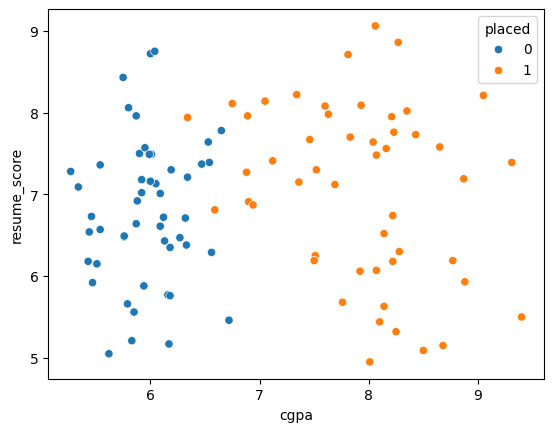

In [41]:
sns.scatterplot(x=df['cgpa'],y=df['resume_score'],hue=df['placed'])

In [42]:
x = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [43]:
x

,cgpa,resume_score
0,8.14,6.52
1,6.17,5.17
2,8.27,8.86
3,6.88,7.27
4,7.52,7.30
...,...,...
95,6.33,6.38
96,8.23,7.76
97,6.65,7.78
98,8.14,5.63


In [44]:
y

0     1
1     0
2     1
3     1
4     1
     ..
95    0
96    1
97    0
98    1
99    0
Name: placed, Length: 100, dtype: int64

In [45]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(x , y , test_size=0.2 , random_state=20)

In [46]:
X_train.shape

(80, 2)

In [47]:
X_test.shape

(20, 2)

In [48]:
from sklearn.linear_model import Perceptron 

In [65]:
p = Perceptron(max_iter=1500)
p.fit(X_train,y_train)

,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1500
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary `.",0


In [60]:
p.coef_  # this are the weights to the perceptorn 

array([[ 35.75, -38.09]])

In [61]:
p.intercept_ # this is bias 

array([-48.])

- formula  => Y_output = 35.75(X1) -38.09(X2) + -48

In [52]:
import sys
!{sys.executable} -m pip install mlxtend


[notice] A new release of pip is available: 25.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [53]:
from mlxtend.plotting import plot_decision_regions

f:\desktop\ML\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but Perceptron was fitted with feature names
  warnings.warn(


<Axes: >

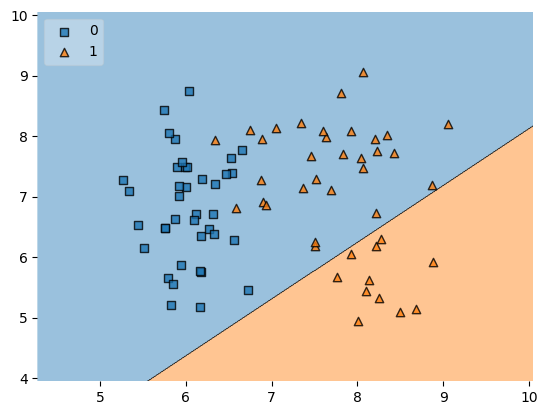

In [66]:
plot_decision_regions(X_train.values,y_train.values,clf = p,legend=2)

In [55]:
from sklearn.metrics import accuracy_score , precision_score

In [56]:
y_pred = p.predict(X_test)

In [57]:
Accuracy = accuracy_score(y_test,y_pred)
Accuracy

0.75